# SimWeave vs Mesa: From Boltzmann Wealth to Logistics, Routing & Optimisation

Mesa's classic *Boltzmann Wealth Model* shows how simple random exchanges
between agents can produce an exponential wealth distribution.

In this notebook, we:

1. Recreate a Boltzmann-style wealth exchange in **SimWeave**.
2. Extend it with:
   - continuous time
   - routing on a grid
   - warehouses and restocking
   - a central depot with queueing and service
   - cost vs availability optimisation

The goal is not to replace Mesa, but to show how SimWeave naturally
extends agent-based models into **logistics, traffic, and optimisation**.


In [1]:
import math
import random
from dataclasses import dataclass

import numpy as np
import plotly.graph_objects as go

import simweave as sw
from simweave.core.entity import Entity
from simweave.core.environment import SimEnvironment
from simweave.spatial.graph import grid_graph
from simweave.agents.agent import Agent
from simweave.agents.routing import manhattan
from simweave.supplychain.inventory import InventoryItems
from simweave.supplychain.warehouse import Warehouse
from simweave.discrete.services import Service, ArrivalGenerator
from simweave.viz import plots as viz


## 1. A minimal wealth-exchange model

We start with a very simple model:

- Each agent has a scalar `wealth`.
- At random times, two agents are chosen and exchange a fraction of wealth.
- Over time, the distribution tends towards an exponential-like shape.

This is conceptually similar to Mesa's Boltzmann Wealth Model, but we
implement it in **continuous time** using SimWeave's `SimEnvironment`.


In [2]:
class Trader(Entity):
    def __init__(self, wealth: float, name: str | None = None) -> None:
        super().__init__(name=name)
        self.wealth = float(wealth)
        self.history: list[tuple[float, float]] = []  # (t, wealth)

    def record(self, env: SimEnvironment) -> None:
        self.history.append((env.clock.t, self.wealth))


In [3]:
class MeetingProcess(Entity):
    """Random pairwise wealth exchanges between traders."""

    def __init__(
        self,
        traders: list[Trader],
        rate: float = 1.0,
        rng: random.Random | None = None,
        name: str | None = None,
    ) -> None:
        super().__init__(name=name)
        self.traders = traders
        self.rate = float(rate)
        self.rng = rng or random.Random()
        # Exponential inter-meeting time
        self._countdown = self._draw_interarrival()

    def _draw_interarrival(self) -> float:
        return self.rng.expovariate(self.rate)

    def tick(self, dt: float, env: SimEnvironment) -> None:
        super().tick(dt, env)
        remaining = dt
        while remaining >= self._countdown:
            remaining -= self._countdown
            self._fire_meeting(env)
            self._countdown = self._draw_interarrival()
        self._countdown -= remaining

    def _fire_meeting(self, env: SimEnvironment) -> None:
        a, b = self.rng.sample(self.traders, 2)
        poorer, richer = (a, b) if a.wealth < b.wealth else (b, a)
        frac = self.rng.uniform(0.0, 0.5)
        delta = frac * poorer.wealth
        poorer.wealth -= delta
        richer.wealth += delta
        for t in self.traders:
            t.record(env)

    def has_work(self, env) -> bool:
        return True  # always has another meeting scheduled


In [4]:
random.seed(0)

n_traders = 50
initial_wealth = 100.0

traders = [Trader(initial_wealth, name=f"trader_{i}") for i in range(n_traders)]
meetings = MeetingProcess(traders, rate=2.0, rng=random.Random(1))

env = SimEnvironment(dt=0.1, end=50.0)
for t in traders:
    env.register(t)
env.register(meetings)

env.run()

final_wealth = np.array([t.wealth for t in traders])


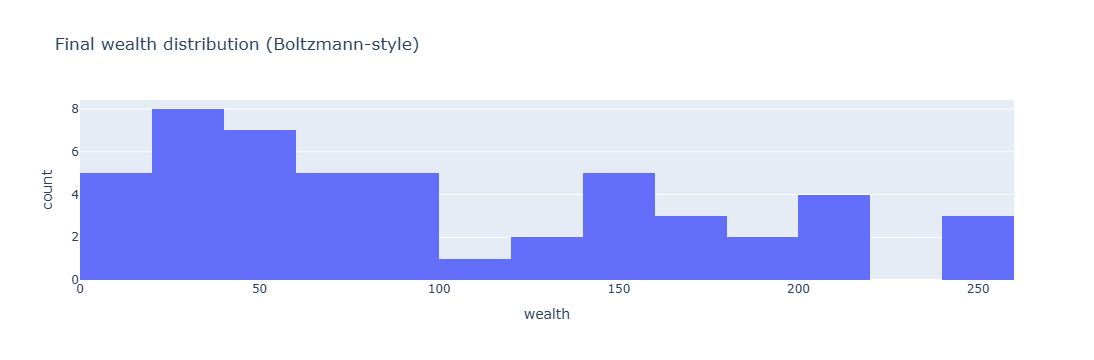

In [5]:
fig = go.Figure()
fig.add_histogram(x=final_wealth, nbinsx=20)
fig.update_layout(
    title="Final wealth distribution (Boltzmann-style)",
    xaxis_title="wealth",
    yaxis_title="count",
)
fig.show()


## 2. Adding movement and routing

Mesa's Boltzmann model is typically non-spatial or uses a simple grid
with discrete steps.

SimWeave already has a routing-capable `Agent` that:

- moves on a graph using A*,
- has a speed,
- tracks history,
- can fire `on_arrive` callbacks.

We'll now:

- place traders on a grid graph,
- give them waypoints,
- let them move continuously,
- only allow wealth exchanges when they **meet at the same node**.


In [6]:
@dataclass
class MobileTrader:
    trader: Trader
    agent: Agent


In [7]:
g = grid_graph(8, 8)

def make_mobile_traders(n: int) -> list[MobileTrader]:
    mobiles: list[MobileTrader] = []
    for i in range(n):
        start = (random.randint(0, 7), random.randint(0, 7))
        tasks = [
            (random.randint(0, 7), random.randint(0, 7))
            for _ in range(3)
        ]
        t = Trader(initial_wealth, name=f"trader_{i}")
        a = Agent(
            graph=g,
            start_node=start,
            tasks=tasks,
            speed=1.0 + random.random(),
            heuristic=manhattan,
            name=f"agent_{i}",
        )
        mobiles.append(MobileTrader(trader=t, agent=a))
    return mobiles

mobiles = make_mobile_traders(20)

env = SimEnvironment(dt=1.0, end=80.0)
for m in mobiles:
    env.register(m.agent)
    env.register(m.trader)


In [8]:
class CoLocationMeetings(Entity):
    """Random meetings, but only between co-located mobile traders."""

    def __init__(
        self,
        mobiles: list[MobileTrader],
        rate: float = 1.0,
        rng: random.Random | None = None,
        name: str | None = None,
    ) -> None:
        super().__init__(name=name)
        self.mobiles = mobiles
        self.rate = float(rate)
        self.rng = rng or random.Random()
        self._countdown = self._draw_interarrival()

    def _draw_interarrival(self) -> float:
        return self.rng.expovariate(self.rate)

    def tick(self, dt: float, env: SimEnvironment) -> None:
        super().tick(dt, env)
        remaining = dt
        while remaining >= self._countdown:
            remaining -= self._countdown
            self._fire_meeting(env)
            self._countdown = self._draw_interarrival()
        self._countdown -= remaining

    def _fire_meeting(self, env: SimEnvironment) -> None:
        # Group by position
        by_pos: dict[tuple[int, int], list[MobileTrader]] = {}
        for m in self.mobiles:
            pos = m.agent.position
            by_pos.setdefault(pos, []).append(m)

        crowded = [group for group in by_pos.values() if len(group) >= 2]
        if not crowded:
            return

        group = self.rng.choice(crowded)
        a, b = self.rng.sample(group, 2)
        ta, tb = a.trader, b.trader

        poorer, richer = (ta, tb) if ta.wealth < tb.wealth else (tb, ta)
        frac = self.rng.uniform(0.0, 0.5)
        delta = frac * poorer.wealth
        poorer.wealth -= delta
        richer.wealth += delta

        for m in self.mobiles:
            m.trader.record(env)

    def has_work(self, env) -> bool:
        return True


In [9]:
meetings = CoLocationMeetings(mobiles, rate=1.0, rng=random.Random(2))
env.register(meetings)

env.run()

final_wealth_mobile = np.array([m.trader.wealth for m in mobiles])


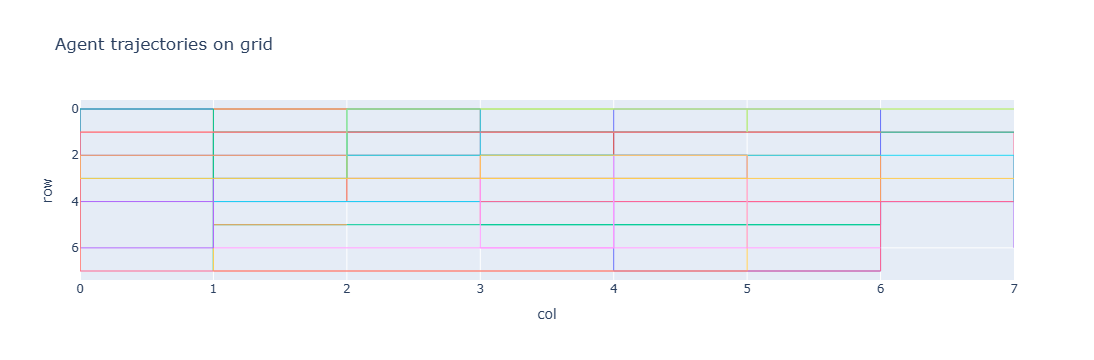

In [10]:
fig = go.Figure()
for m in mobiles:
    xs = [pos[1] for _, pos in m.agent.history]
    ys = [pos[0] for _, pos in m.agent.history]
    fig.add_trace(
        go.Scatter(
            x=xs,
            y=ys,
            mode="lines",
            name=m.trader.name,
            line={"width": 1},
            showlegend=False,
        )
    )

fig.update_layout(
    title="Agent trajectories on grid",
    xaxis_title="col",
    yaxis_title="row",
    yaxis_autorange="reversed",
)
fig.show()


## 3. Adding warehouses: each trader holds inventory

Now we connect wealth to **inventory**:

- Each trader has a small warehouse.
- Each trade consumes one unit of stock.
- When stock falls below a reorder point, the warehouse reorders from its parent.
- Reorders have a lead time and are handled automatically in `Warehouse.tick()`.

This uses SimWeave's `InventoryItems` and `Warehouse`.


In [11]:
def make_trader_warehouse(name: str, n_skus: int = 3) -> Warehouse:
    inv = InventoryItems(
        part_names=[f"sku_{i}" for i in range(n_skus)],
        unit_cost=np.random.uniform(1, 10, size=n_skus),
        stock_level=[20.0] * n_skus,
        batchsize=[10.0] * n_skus,
        reorder_points=[5.0] * n_skus,
        repairable_prc=[0.0] * n_skus,
        repair_times=[1.0] * n_skus,
        newbuy_leadtimes=[3.0] * n_skus,
    )
    return Warehouse(inventory=inv, name=f"{name}_wh")

In [12]:
@dataclass
class TraderPreferences:
    demand_weights: np.ndarray  # relative importance of each SKU
    
@dataclass
class TraderWithWarehouse:
    trader: Trader
    agent: Agent
    warehouse: Warehouse
    prefs: TraderPreferences


In [13]:
def make_traders_with_warehouses(n: int, n_skus: int=3) -> list[TraderWithWarehouse]:
    tws: list[TraderWithWarehouse] = []
    for i in range(n):
        start = (random.randint(0, 7), random.randint(0, 7))
        tasks = [
            (random.randint(0, 7), random.randint(0, 7))
            for _ in range(3)
        ]
        t = Trader(initial_wealth, name=f"trader_{i}")
        a = Agent(
            graph=g,
            start_node=start,
            tasks=tasks,
            speed=1.0 + random.random(),
            heuristic=manhattan,
            name=f"agent_{i}",
        )
        w = make_trader_warehouse(t.name, n_skus=n_skus)
        prefs = TraderPreferences(
            demand_weights=np.random.dirichlet(np.ones(n_skus))
        )
        tws.append(TraderWithWarehouse(trader=t, agent=a, warehouse=w, prefs=prefs))
    return tws

tws = make_traders_with_warehouses(10)

env = SimEnvironment(dt=1.0, end=80.0)
for tw in tws:
    env.register(tw.agent)
    env.register(tw.warehouse)
    env.register(tw.trader)


In [14]:
def utility(tw):
    inv = tw.warehouse.inv.stock_level
    return tw.trader.wealth + np.dot(inv, tw.prefs.demand_weights)

In [15]:
def can_trade(tw_a, tw_b, demand_vec):
        inv_a = tw_a.warehouse.inv.stock_level
        inv_b = tw_b.warehouse.inv.stock_level
        return (inv_a >= demand_vec).all() and (inv_b >= demand_vec).all()
    
class InventoryTrades(Entity):
    """Trades that consume stock from each trader's warehouse."""

    def __init__(
        self,
        tws: list[TraderWithWarehouse],
        rate: float = 1.0,
        rng: random.Random | None = None,
        name: str | None = None,
    ) -> None:
        super().__init__(name=name)
        self.tws = tws
        self.rate = float(rate)
        self.rng = rng or random.Random()
        self._countdown = self._draw_interarrival()

    @staticmethod
    def draw_consumption_vector(n_skus: int, prefs) -> np.ndarray:
        # Weighted by trader preferences
        idx = np.random.choice(n_skus, p=prefs)
        vec = np.zeros(n_skus)
        vec[idx] = 1.0
        return vec
   
    def _draw_interarrival(self) -> float:
        return self.rng.expovariate(self.rate)

    def tick(self, dt: float, env: SimEnvironment) -> None:
        super().tick(dt, env)
        remaining = dt
        while remaining >= self._countdown:
            remaining -= self._countdown
            self._fire_trade(env)
            self._countdown = self._draw_interarrival()
        self._countdown -= remaining

    def _fire_trade(self, env: SimEnvironment) -> None:
        # 1. Group by position
        by_pos: dict[tuple[int, int], list[TraderWithWarehouse]] = {}
        for tw in self.tws:
            pos = tw.agent.position
            by_pos.setdefault(pos, []).append(tw)
    
        crowded = [group for group in by_pos.values() if len(group) >= 2]
        if not crowded:
            return
    
        # 2. Pick two co-located traders
        group = self.rng.choice(crowded)
        a, b = self.rng.sample(group, 2)
        ta, tb = a.trader, b.trader

        # Calc what wealth exchange will be
        poorer, richer = (ta, tb) if ta.wealth < tb.wealth else (tb, ta)
        frac = self.rng.uniform(0.0, 0.5)
        delta = frac * poorer.wealth
      
        # 3. MULTI-SKU: draw a demand vector
        n_skus = a.warehouse.inv.n_items
        # Use the *average* of both traders' preferences,
        # or choose one trader’s preferences — your choice.
        prefs = (a.prefs.demand_weights + b.prefs.demand_weights) / 2
        demand_vec = self.draw_consumption_vector(n_skus, prefs)
    
        # 4. utility-based trade decision
        u_before = utility(a) + utility(b)

        # simulate post-trade inventories
        inv_a_new = a.warehouse.inv.stock_level - demand_vec
        inv_b_new = b.warehouse.inv.stock_level - demand_vec
        
        u_after = (
            (a.trader.wealth + delta) + np.dot(inv_a_new, a.prefs.demand_weights) +
            (b.trader.wealth - delta) + np.dot(inv_b_new, b.prefs.demand_weights)
        )
 
    
        # 5. MULTI-SKU: check availability
        if not can_trade(a, b, demand_vec):
            return
    
        # 6. MULTI-SKU: decrement stock
        a.warehouse.decrement_vector(demand_vec)
        b.warehouse.decrement_vector(demand_vec)
    
        # 7. Wealth exchange
        poorer.wealth -= delta
        richer.wealth += delta
    
        # 8. Record history
        for tw in self.tws:
            tw.trader.record(env)

        # Log trade event for animation
        env._trade_events.append((env.clock.t, a.agent.position))
    
    
    def has_work(self, env) -> bool:
        return True

In [16]:
trades = InventoryTrades(tws, rate=1.0, rng=random.Random(3))
env._trade_events = [] # for GIF animation
env.register(trades)

env.run()

final_wealth_inv = np.array([tw.trader.wealth for tw in tws])
stock_levels = np.array([tw.warehouse.inv.stock_level[0] for tw in tws])


## 4. Central depot with queueing and service

Now we introduce a **central depot**:

- Located at the centre of the grid, e.g. `(4, 4)` on an 8×8 grid.
- Modelled as a `Service` with capacity 1 (single server).
- Traders travel to the depot when their stock falls below a threshold.
- They wait in a queue, get serviced (restocked), then return to their route.

This uses SimWeave's `Service` and queueing abstractions.


In [17]:
class RestockJob(Entity):
    def __init__(self, owner: TraderWithWarehouse, name: str | None = None) -> None:
        super().__init__(name=name)
        self.owner = owner
        self.remaining_service_time: float = 0.0
        self.total_wait_time: float = 0.0  # used by Service metrics


In [18]:
DEPOT_NODE = (4, 4)

depot = Service(
    capacity=1,
    buffer_size=20,
    next_q="terminus",
    default_service_time=5.0,
    name="central_depot",
)

env = SimEnvironment(dt=1.0, end=120.0)
for tw in tws:
    env.register(tw.agent)
    env.register(tw.warehouse)
    env.register(tw.trader)
env.register(depot)


Service(name='central_depot', len=0/20, next=terminus)

We’ll add a small controller entity that:

watches each trader’s warehouse

when stock ≤ reorder point, appends the depot to the agent’s tasks

when the agent reaches the depot, enqueues a RestockJob into the depot service

In [19]:
class DepotController(Entity):
    """Routes traders to depot when low on stock and enqueues restock jobs."""

    def __init__(self, tws: list[TraderWithWarehouse], depot: Service, name=None):
        super().__init__(name=name)
        self.tws = tws
        self.depot = depot
        # Track whether a trader is already en route / queued
        self._in_progress: set[int] = set()

    def tick(self, dt: float, env: SimEnvironment) -> None:
        super().tick(dt, env)
        for tw in self.tws:
            inv = tw.warehouse.inv
            # If stock below reorder point and not already in progress, send to depot
            if (
                inv.stock_level[0] <= inv.reorder_points[0]
                and tw not in self._in_progress
            ):
                # Append depot node to tasks if not already there
                if DEPOT_NODE not in tw.agent.tasks and tw.agent.position != DEPOT_NODE:
                    tw.agent.tasks.append(DEPOT_NODE)
                # mark as in progress
                self._in_progress.add(id(tw))
                
            # If at depot and in progress, enqueue a restock job
            if id(tw) in self._in_progress and tw.agent.position == DEPOT_NODE:
                job = RestockJob(owner=tw, name=f"restock_{tw.trader.name}")
                # Service will assign remaining_service_time if needed
                accepted = self.depot.enqueue(job)
                if accepted:
                    self._in_progress.remove(tw)

    def has_work(self, env) -> bool:
        return True

controller = DepotController(tws, depot, name="depot_controller")
env.register(controller)

DepotController(name='depot_controller', id=124)

In [20]:
def depot_record_completion(item: RestockJob):
    tw = item.owner
    inv = tw.warehouse.inv
    # Simple policy: add one batch
    inv.stock_level[0] += inv.batchsize[0]

# Monkey-patch the depot's completion hook for this demo
depot._record_completion = depot_record_completion  # type: ignore[attr-defined]


In [21]:
# Rebuild environment to include everything together
env = SimEnvironment(dt=1.0, end=200.0)
env._trade_events = [] # for GIF animation

for tw in tws:
    env.register(tw.agent)
    env.register(tw.warehouse)
    env.register(tw.trader)

depot = Service(
    capacity=1,
    buffer_size=20,
    next_q="terminus",
    default_service_time=5.0,
    name="central_depot",
)
env.register(depot)

controller = DepotController(tws, depot, name="depot_controller")
env.register(controller)

trades = InventoryTrades(tws, rate=1.0, rng=random.Random(4))
env.register(trades)

# Patch completion hook again
depot._record_completion = depot_record_completion  # type: ignore[attr-defined]

env.run()

final_wealth_depot = np.array([tw.trader.wealth for tw in tws])
final_stock_depot = np.array([tw.warehouse.inv.stock_level[0] for tw in tws])


## 5. Optimising stock: cost vs availability

Finally, we connect the simulation to SimWeave's optimisation layer.

We:

1. Take a warehouse (or aggregate demand from several).
2. Use `estimate_demand_rate(total_sim_time)` to infer demand.
3. Run `pareto_sweep` and `plot_pareto_sweep` to explore the cost vs availability frontier.


In [22]:
total_time = env.clock.t

# Take one trader's warehouse as a representative
wh = tws[0].warehouse

# Idiomatic SimWeave: estimate demand from lifetime orders
demand_rate = wh.estimate_demand_rate(total_time)
demand_rate


array([0.1, 0.1, 0.1])

In [23]:
### this is added in v0.8.2
from typing import Any
from simweave.supplychain.optimization import pareto_sweep
from simweave.viz import _plotly
from simweave.viz.themes import apply_theme

def plot_pareto_sweep(
    warehouse: Warehouse,
    availability_range: np.ndarray | None = None,
    *,
    theme: str | None = None,
    title: str | None = None,
) -> Any:
    """Plot cost vs availability with optional DE and Poisson curves.

    Parameters
    ----------
    warehouse:
        Warehouse instance to optimise.
    availability_range:
        Optional array of availability targets.
    theme:
        Optional Plotly theme.
    title:
        Optional plot title.
    """
    go = _plotly.require_go()

    sweep = pareto_sweep(warehouse, availability_range)
    a = sweep["availability"]

    fig = go.Figure()

    # Poisson heuristic
    if "cost_poisson" in sweep:
        c_p = sweep["cost_poisson"]
        fig.add_trace(
            go.Scatter(
                x=c_p,
                y=a,
                mode="lines+markers",
                name="Poisson heuristic",
                line={"dash": "dash", "width": 2},
            )
        )

    # DE cost-optimal
    if "cost_cost_optimal" in sweep:
        c_de = sweep["cost_cost_optimal"]
        fig.add_trace(
            go.Scatter(
                x=c_de,
                y=a,
                mode="lines+markers",
                name="cost-optimal (DE)",
                line={"width": 2},
            )
        )

        # Shaded savings region (only if Poisson also present)
        if "cost_poisson" in sweep:
            fig.add_trace(
                go.Scatter(
                    x=np.concatenate([c_p, c_de[::-1]]),
                    y=np.concatenate([a, a[::-1]]),
                    fill="toself",
                    fillcolor="rgba(0, 150, 0, 0.1)",
                    line={"width": 0},
                    name="savings region",
                    hoverinfo="skip",
                    showlegend=True,
                )
            )

    wname = getattr(warehouse, "name", "warehouse")

    fig.update_layout(
        title=title or f"cost vs availability: {wname}",
        xaxis_title="total cost",
        yaxis_title="target availability",
        legend_title_text="method",
    )

    return apply_theme(fig, theme)


In [ ]:
availability_range = np.linspace(0.5, 0.95, 6)

fig = plot_pareto_sweep(
    wh,
    availability_range=availability_range,
    title="Cost vs availability for trader warehouse",
)
fig.show()


## 6. Wealth Distributions

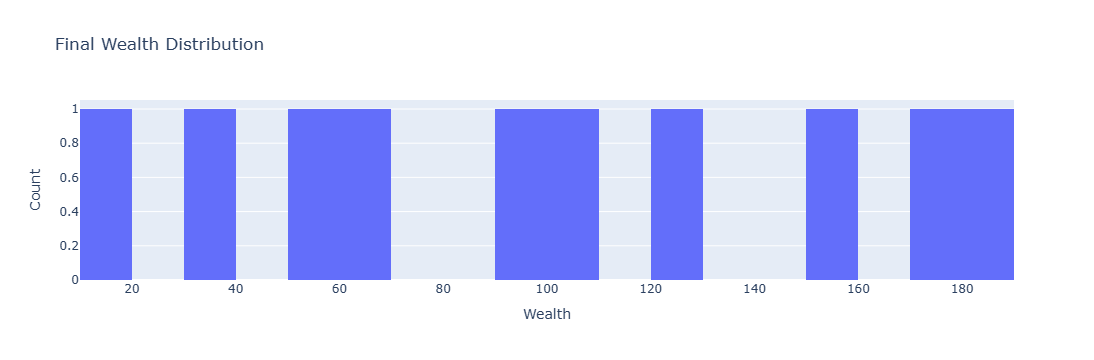

In [25]:
wealths = np.array([tw.trader.wealth for tw in tws])

fig = go.Figure()
fig.add_histogram(x=wealths, nbinsx=20)
fig.update_layout(
    title="Final Wealth Distribution",
    xaxis_title="Wealth",
    yaxis_title="Count",
)
fig.show()


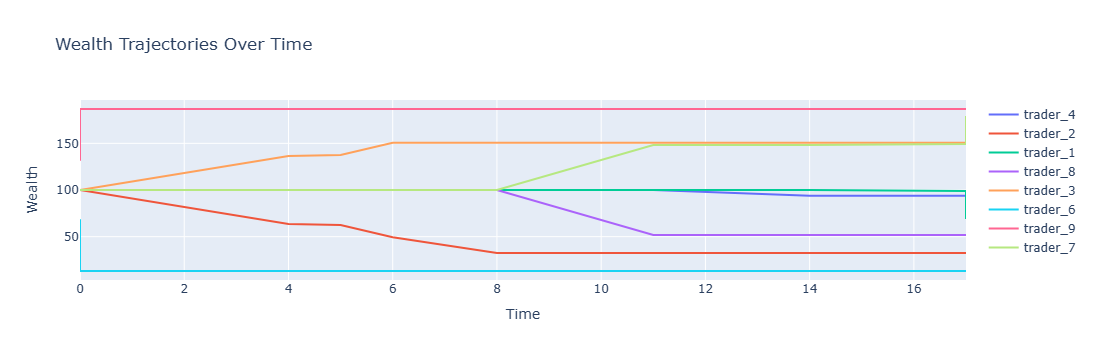

In [26]:
# through time
fig = go.Figure()

for tw in random.sample(tws, k=min(8, len(tws))):
    times = [t for (t, _) in tw.trader.history]
    vals = [w for (_, w) in tw.trader.history]
    fig.add_trace(go.Scatter(x=times, y=vals, mode="lines", name=tw.trader.name))

fig.update_layout(
    title="Wealth Trajectories Over Time",
    xaxis_title="Time",
    yaxis_title="Wealth",
)
fig.show()


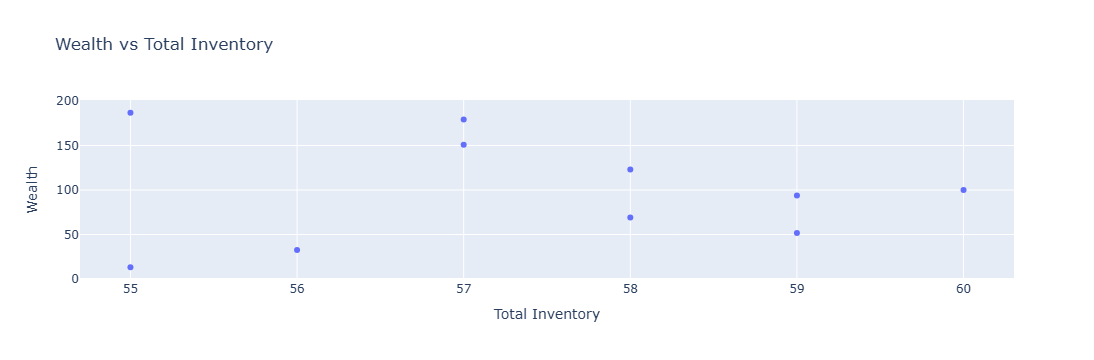

In [27]:
# Wealth vs total inventory
wealths = np.array([tw.trader.wealth for tw in tws])
stocks = np.array([tw.warehouse.inv.stock_level.sum() for tw in tws])

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=stocks,
    y=wealths,
    mode="markers",
))
fig.update_layout(
    title="Wealth vs Total Inventory",
    xaxis_title="Total Inventory",
    yaxis_title="Wealth",
)
fig.show()


## 7. Conclusion

We started with a Mesa-style Boltzmann wealth model and then:

- moved to **continuous time**,
- added **routing on a grid** with A*,
- coupled wealth to **inventory and warehouses**,
- introduced a **central depot with queueing and service**,
- and finally used **optimisation** to explore the cost vs availability trade-off.

Mesa is excellent for discrete, grid-based agent models.

SimWeave takes you further into:

- logistics,
- traffic,
- queues and services,
- and optimisation — all in one coherent framework.

This is where SimWeave stops being "just an ABM framework" and becomes a
**full-stack simulation and optimisation platform**.


In [ ]:
!python -m pip install imageio

In [29]:
import imageio
import numpy as np
import plotly.graph_objects as go
from pathlib import Path

def animate_agents(
    agents,
    grid_shape,
    outfile="agents.gif",
    fps=5,
    marker_size=12,
    trail_length=10,
    figsize=(500, 500),
    dt=1.0
):
    """
    Create a GIF animation of agent movement on a grid.

    Parameters
    ----------
    agents : list[Agent]
        Agents with a `.history` attribute: list of (t, (row, col)).
    grid_shape : tuple[int, int]
        (rows, cols) of the grid.
    outfile : str
        Output GIF filename.
    fps : int
        Frames per second.
    marker_size : int
        Size of agent markers.
    trail_length : int
        Number of past positions to show as a trail.
    figsize : tuple[int, int]
        Pixel size of each frame.
    """

    # Collect all unique times across all agents
    times = sorted({t for a in agents for (t, _) in a.history})
    frames = []

    # Build a lookup: agent -> dict(time -> position)
    lookup = []
    for a in agents:
        d = {t: pos for (t, pos) in a.history}
        lookup.append(d)

    rows, cols = grid_shape

    for t in times:
        fig = go.Figure()

        # Draw grid background
        fig.add_trace(
            go.Scatter(
                x=[0, cols - 1],
                y=[0, rows - 1],
                mode="markers",
                marker=dict(size=0.1, opacity=0),
                showlegend=False,
            )
        )

        # Plot each agent
        for idx, a in enumerate(agents):
            d = lookup[idx]

            # Find the latest time <= t
            past_times = [pt for pt in d.keys() if pt <= t]
            if not past_times:
                continue
            latest = max(past_times)
            r, c = d[latest]

            # Plot trail
            trail_pts = sorted([pt for pt in past_times if t - pt <= trail_length])
            trail_x = [d[pt][1] for pt in trail_pts]
            trail_y = [d[pt][0] for pt in trail_pts]

            fig.add_trace(
                go.Scatter(
                    x=trail_x,
                    y=trail_y,
                    mode="lines",
                    line=dict(width=2, color="rgba(0,0,150,0.3)"),
                    showlegend=False,
                )
            )

            # Plot agent marker
            fig.add_trace(
                go.Scatter(
                    x=[c],
                    y=[r],
                    mode="markers",
                    marker=dict(size=marker_size),
                    name=a.name,
                    showlegend=False,
                )
            )

        # NOW highlight trades (outside agent loop)
        trade_positions = [
            pos for (t_evt, pos) in env._trade_events
            if abs(t_evt - t) <= dt/2
        ]
    
        for (r, c) in trade_positions:
            fig.add_trace(go.Scatter(
                x=[c], y=[r],
                mode="markers",
                marker=dict(size=marker_size*3, color="rgba(255,0,0,0.25)"),
                showlegend=False,
            ))
            fig.add_trace(go.Scatter(
                x=[c], y=[r],
                mode="markers",
                marker=dict(size=marker_size*1.8, color="red"),
                showlegend=False,
            ))


        fig.update_layout(
            width=figsize[0],
            height=figsize[1],
            xaxis=dict(range=[-0.5, cols - 0.5], title="col"),
            yaxis=dict(range=[-0.5, rows - 0.5], title="row", autorange="reversed"),
            margin=dict(l=10, r=10, t=10, b=10),
        )

        # Export frame to PNG in memory
        png_bytes = fig.to_image(format="png")
        frames.append(imageio.v2.imread(png_bytes))

    # Save GIF
    imageio.mimsave(outfile, frames, fps=fps)
    return Path(outfile)


In [30]:
animate_agents(
    agents=[tw.agent for tw in tws],
    grid_shape=(8, 8),
    outfile="movement.gif",
    fps=4,
)


WindowsPath('movement.gif')